In [76]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from autorank import autorank, plot_stats, create_report
from itertools import permutations
from scipy.stats import bootstrap, wilcoxon

from deepfake.constants import WAVELET_FAMILIES
from deepfake.data import frequency_ordered_nodes

In [55]:
df = pd.read_csv("./results/train_all/results.csv")
df["eer"] = df["eer"] * 100
df.head()

,seed,pooling,wavelet,node,eval_split,eer,roc_auc,best_epoch,best_dev_eer,train_time_s
0,42,wavelet,db4,aaa,ASVspoof 2019,8.905494,0.968398,7,0.070244,1560.8
1,42,wavelet,db4,aad,ASVspoof 2019,5.995675,0.983775,10,0.047891,1957.2
2,42,wavelet,db4,add,ASVspoof 2019,7.519405,0.976639,26,0.048665,3739.5
3,42,wavelet,db4,ada,ASVspoof 2019,7.475530,0.976887,10,0.059323,1899.2
4,42,wavelet,db4,dda,ASVspoof 2019,10.034058,0.962619,18,0.086340,2872.3


In [56]:
df_2019 = df[df["eval_split"] == "ASVspoof 2019"]
df_2021 = df[df["eval_split"] == "ASVspoof 2021"]

In [57]:
df_2019.shape, df_2021.shape

((210, 10), (210, 10))

In [58]:
nodes = frequency_ordered_nodes(level=3)
wavelets = WAVELET_FAMILIES

columns = [
    f"{wavelet}_{node}"
    for wavelet in wavelets
    for node in nodes
] + ["average", "max"]

## ASVspoof 2019

In [59]:
df_2019["configuration"] = np.where(
    df_2019["pooling"] == "wavelet",
    df_2019["wavelet"] + "_" + df_2019["node"],
    df_2019["pooling"]
)

autorank_input_2019 = df_2019.pivot_table(
    index="seed",
    columns="configuration",
    values="eer",
    aggfunc="mean"
)

autorank_input_2019 = autorank_input_2019[columns]

autorank_input_2019

configuration,db4_aaa,db4_aad,db4_add,db4_ada,db4_dda,db4_ddd,db4_dad,db4_daa,db8_aaa,db8_aad,...,db38_aaa,db38_aad,db38_add,db38_ada,db38_dda,db38_ddd,db38_dad,db38_daa,average,max
seed,,,,,,,,,,,,,,,,,,,,,
42,8.905494,5.995675,7.519405,7.475530,10.034058,9.531284,7.952185,22.284499,6.539193,6.810561,...,7.927631,15.026533,12.835486,11.826808,12.086681,18.450620,20.464065,25.903162,6.717578,4.921698
52,5.356826,5.017029,7.980652,8.390443,9.994096,10.372289,7.802267,18.751238,9.098504,6.471547,...,6.648367,12.195854,16.098945,11.880612,11.842215,19.728319,16.830777,23.399220,6.773730,5.289180
62,5.831132,5.313733,8.521822,8.305041,9.830336,9.109216,8.659463,20.785323,7.681600,6.446993,...,8.296678,13.743356,13.934800,12.225105,13.227522,19.945883,16.275764,23.252434,4.814090,4.949383
72,4.691074,5.353695,8.415780,7.668540,11.025764,9.718815,8.075983,22.719627,5.438314,6.648367,...,6.863583,17.729500,13.326766,13.011523,12.155110,18.571288,15.538453,23.437617,5.087806,4.746444
82,7.886104,5.835046,8.021396,7.083495,10.454561,10.591419,8.810163,22.176108,6.772165,11.050318,...,9.149960,11.433990,13.581161,11.625434,12.671727,23.060206,14.981093,23.450676,4.935540,4.024541


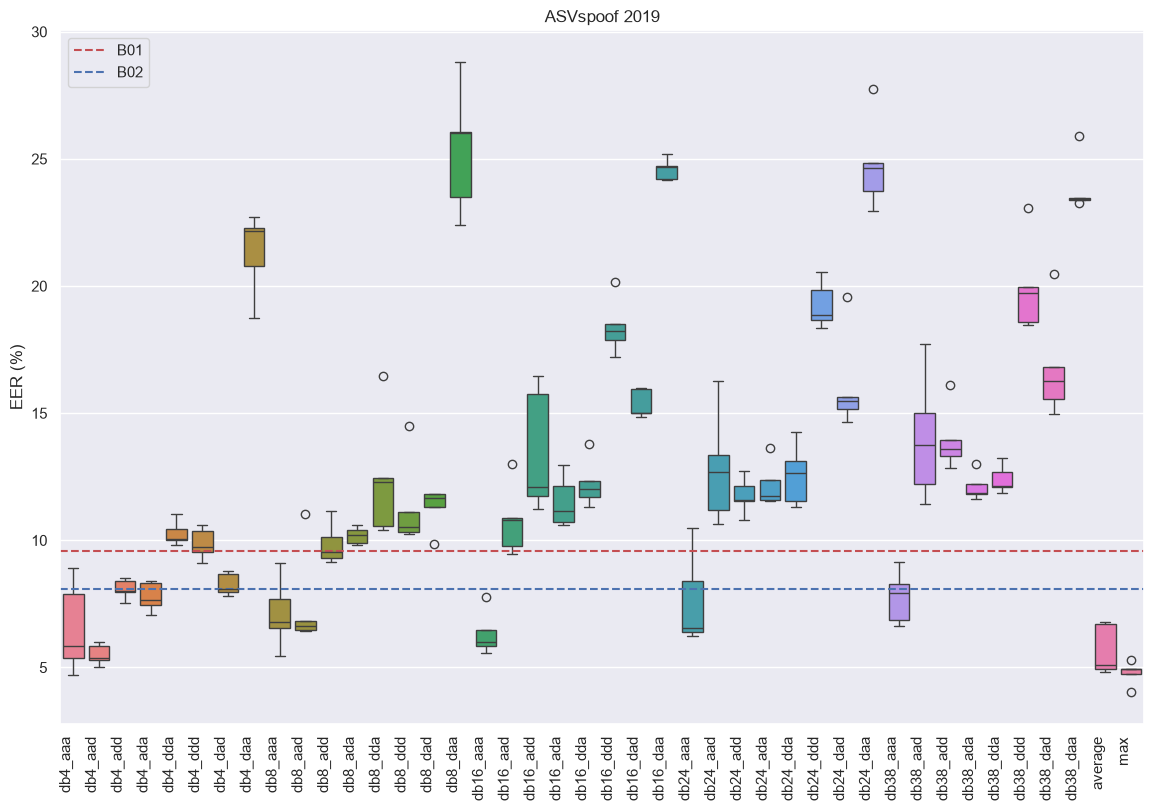

In [60]:
sns.set_theme(rc={'figure.figsize':(11.7,8.27)})
sns.boxplot(data=autorank_input_2019)
plt.title("ASVspoof 2019")

baseline_b01 = 0.0957 * 100
baseline_b02 = 0.0809 * 100

plt.axhline(baseline_b01, color='r', linestyle='--', label='B01')
plt.axhline(baseline_b02, color='b', linestyle='--', label='B02')

plt.xticks(rotation=90, ha='right')

plt.xlabel("")
plt.ylabel("EER (%)")
plt.tight_layout()
plt.legend(loc="upper left")
plt.show()

In [61]:
result_2019 = autorank(autorank_input_2019, alpha=0.05, verbose=False, order='ascending')
print(result_2019)

          meanrank     median       mad   ci_lower   ci_upper effect_size  \
max            1.6   4.921698  0.175254   4.024541    5.28918         0.0   
db4_aad        2.6   5.353695  0.336666   5.017029   5.995675   -1.085683   
average        3.8   5.087806  0.273716    4.81409    6.77373   -0.487505   
db16_aaa       4.8   5.995675  0.437476   5.558199    7.77693   -2.173765   
db4_aaa        5.6   5.831132  1.140058   4.691074   8.905494   -0.752079   
db8_aaa        6.4   6.772165  0.909434   5.438314   9.098504   -1.905825   
db24_aaa       8.6   6.553036  0.312112   6.240924  10.469186   -4.347232   
db8_aad        8.8   6.648367   0.17682   6.446993  11.050318   -6.615719   
db4_ada        8.8   7.668540  0.585045   7.083495   8.390443   -4.290173   
db38_aaa       9.0   7.927631  1.064048   6.648367    9.14996   -2.658868   
db4_add       10.0   8.021396  0.394383   7.519405   8.521822   -6.851088   
db4_dad       10.4   8.075983  0.273716   7.802267   8.810163   -9.257403   

In [62]:
summary_2019 = pd.DataFrame({
    "Mean EER": autorank_input_2019.mean(),
    "Std EER": autorank_input_2019.std(ddof=1),
    "Mean Rank": result_2019.rankdf["meanrank"]
})

summary_2019 = summary_2019.sort_values("Mean Rank")

print(summary_2019)

           Mean EER   Std EER  Mean Rank
max        4.786249  0.468957        1.6
db4_aad    5.503036  0.402264        2.6
average    5.665749  0.990772        3.8
db16_aaa   6.332547  0.874059        4.8
db4_aaa    6.534126  1.783838        5.6
db8_aaa    7.105955  1.370700        6.4
db24_aaa   7.614110  1.820077        8.6
db4_ada    7.784610  0.556428        8.8
db8_aad    7.485557  1.998178        8.8
db38_aaa   7.777244  1.035123        9.0
db4_add    8.091811  0.398381       10.0
db4_dad    8.260012  0.447320       10.4
db8_add    9.846947  0.816498       14.2
db4_ddd    9.864605  0.610117       14.2
db4_dda   10.267763  0.482263       15.0
db8_ada   10.189826  0.346384       15.6
db16_aad  10.778373  1.391995       18.6
db8_ddd   11.343569  1.793113       20.4
db8_dad   11.298071  0.839023       20.6
db16_ada  11.516417  1.012138       21.4
db24_add  11.763026  0.729575       22.6
db8_dda   12.434783  2.444796       23.8
db24_ada  12.174333  0.875178       24.2
db38_ada  12.113

In [63]:
create_report(result_2019)

The statistical analysis was conducted for 42 populations with 5 paired samples.
The family-wise significance level of the tests is alpha=0.050.
We rejected the null hypothesis that the population is normal for the populations db16_dad (p=0.001) and db24_dad (p=0.001). Therefore, we assume that not all populations are normal.
Because we have more than two populations and the populations and some of them are not normal, we use the non-parametric Friedman test as omnibus test to determine if there are any significant differences between the median values of the populations. We use the post-hoc Nemenyi test to infer which differences are significant. We report the median (MD), the median absolute deviation (MAD) and the mean rank (MR) among all populations over the samples. Differences between populations are significant, if the difference of the mean rank is greater than the critical distance CD=30.341 of the Nemenyi test.
We reject the null hypothesis (p=0.000) of the Friedman test that

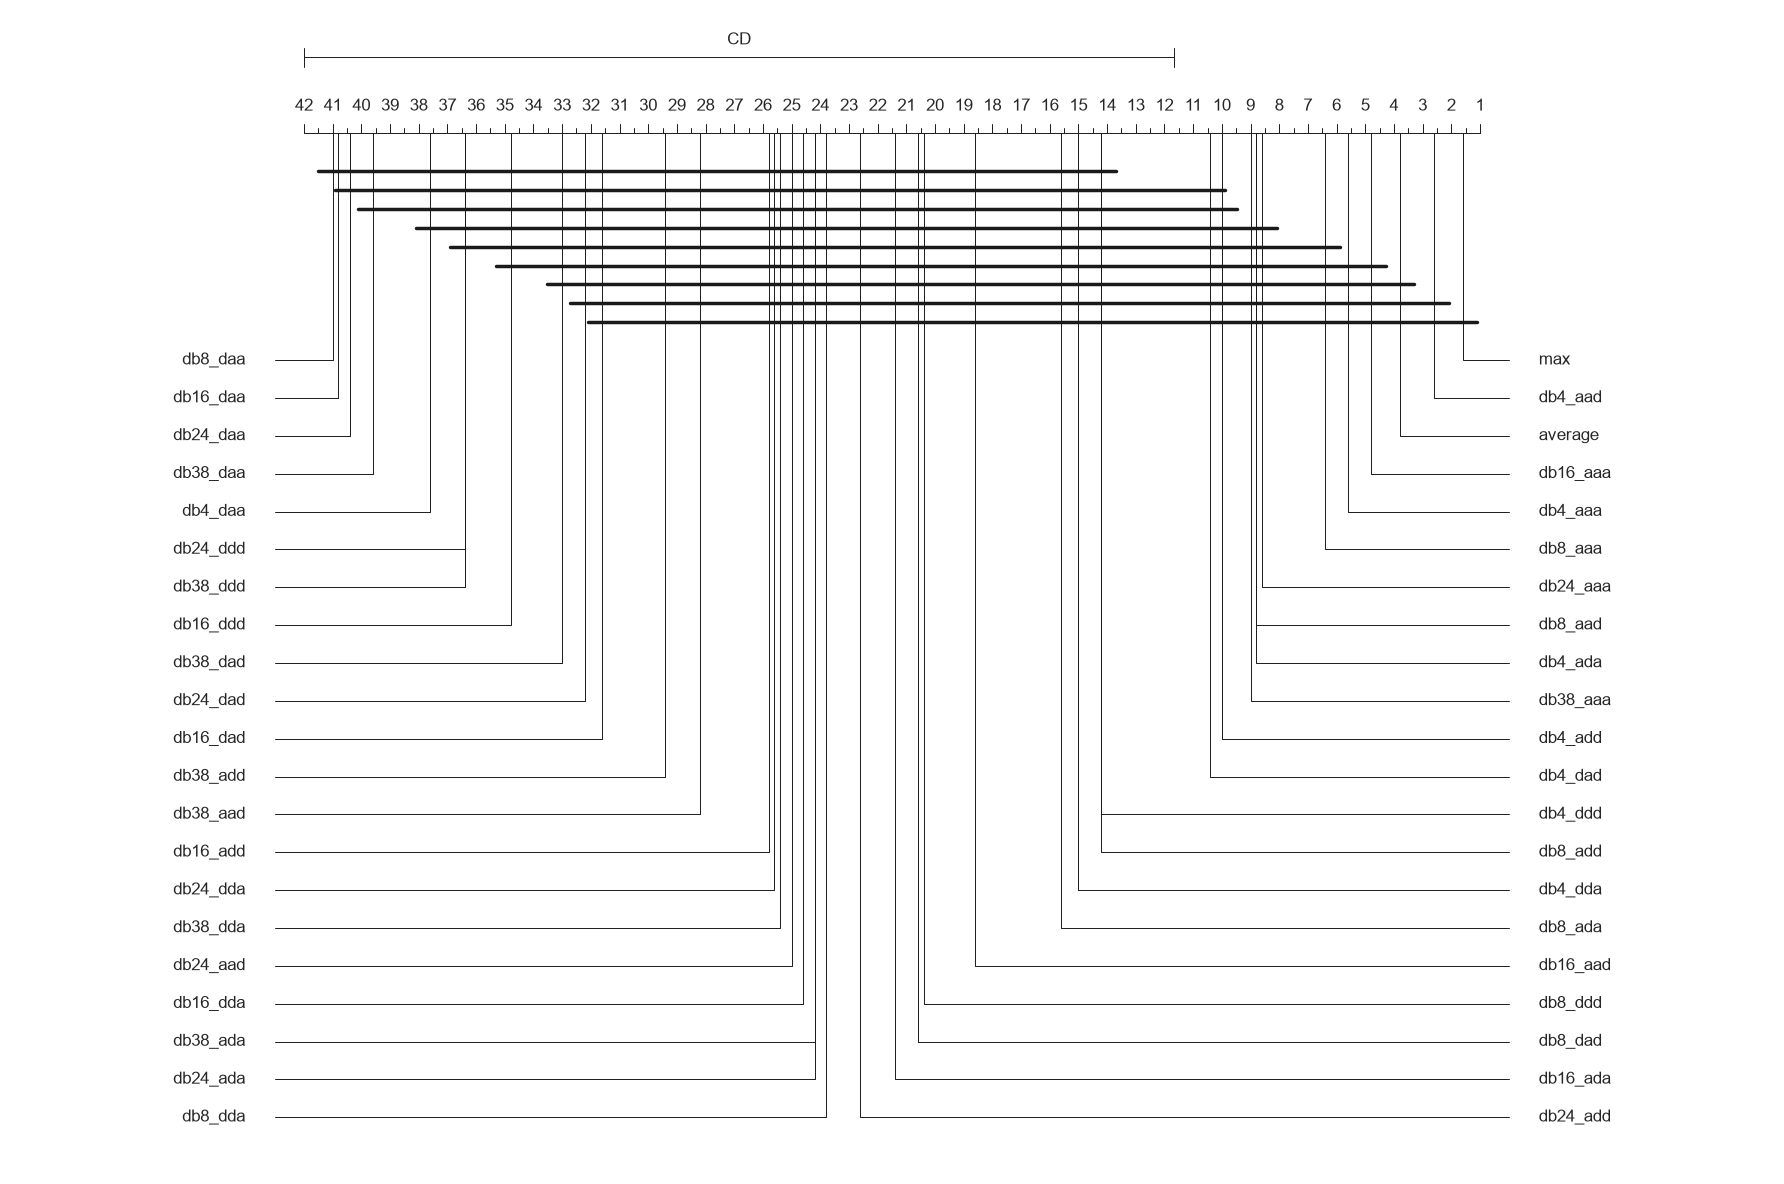

In [64]:
fig, ax = plt.subplots(figsize=(18, 12))

plot_stats(
    result_2019,
    allow_insignificant=True,
    ax=ax
)

plt.tight_layout()
plt.show()

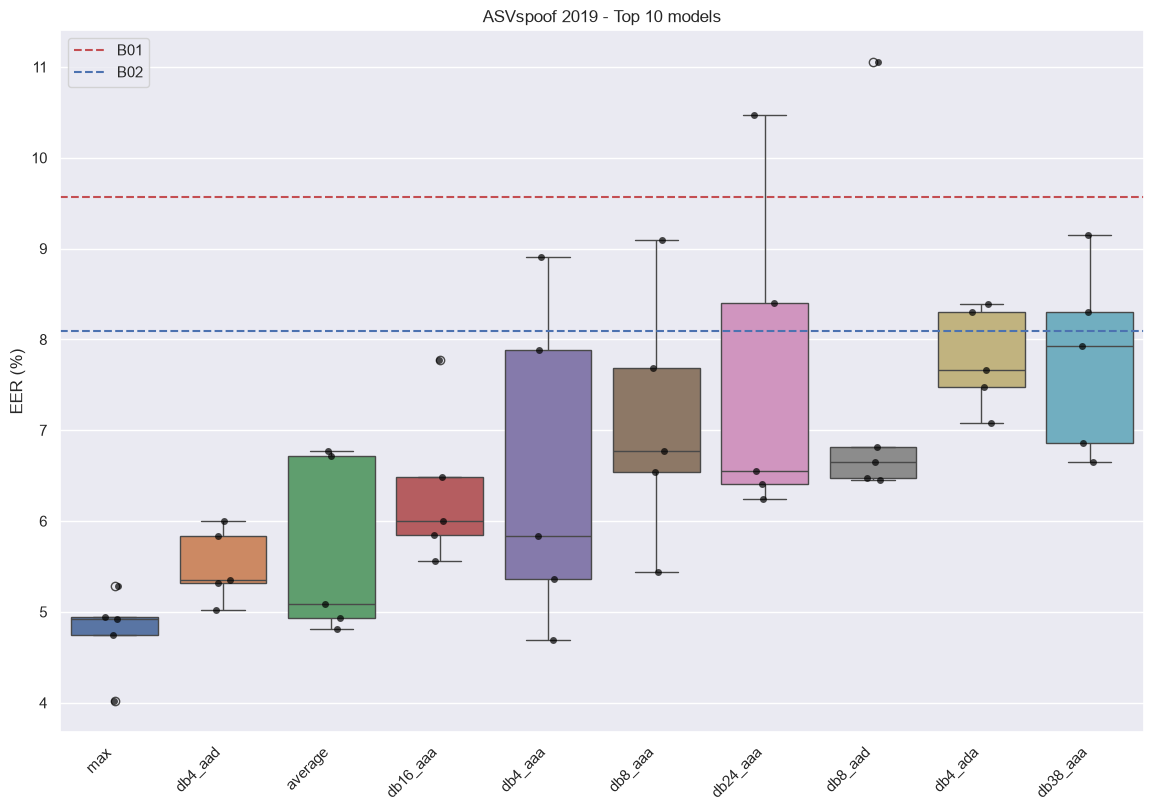

In [65]:
autorank_2019_ranking = result_2019[0]
top_10_results_ranking = autorank_2019_ranking[:10]
top_10_results = autorank_input_2019[top_10_results_ranking.index]

sns.boxplot(data=top_10_results)
sns.stripplot(data=top_10_results, color='black', alpha=0.7)
plt.title("ASVspoof 2019 - Top 10 models")

baseline_b01 = 0.0957 * 100
baseline_b02 = 0.0809 * 100

plt.axhline(baseline_b01, color='r', linestyle='--', label='B01')
plt.axhline(baseline_b02, color='b', linestyle='--', label='B02')

plt.xticks(rotation=45, ha='right')

plt.xlabel("")
plt.ylabel("EER (%)")
plt.tight_layout()
plt.legend(loc="upper left")
plt.show()

In [66]:
bayesian_result_2019 = autorank(
    autorank_input_2019, 
    alpha=0.05, 
    approach='bayesian', 
    rope=0.1,
    verbose=False, 
    order='ascending'
)

          meanrank     median       mad   ci_lower   ci_upper effect_size  \
max            1.6   4.921698  0.175254   4.024541    5.28918         0.0   
average        3.8   5.087806  0.273716    4.81409    6.77373   -0.487505   
db4_aad        2.6   5.353695  0.336666   5.017029   5.995675   -1.085683   
db4_aaa        5.6   5.831132  1.140058   4.691074   8.905494   -0.752079   
db16_aaa       4.8   5.995675  0.437476   5.558199    7.77693   -2.173765   
db24_aaa       8.6   6.553036  0.312112   6.240924  10.469186   -4.347232   
db8_aad        8.8   6.648367   0.17682   6.446993  11.050318   -6.615719   
db8_aaa        6.4   6.772165  0.909434   5.438314   9.098504   -1.905825   
db4_ada        8.8   7.668540  0.585045   7.083495   8.390443   -4.290173   
db38_aaa       9.0   7.927631  1.064048   6.648367    9.14996   -2.658868   
db4_add       10.0   8.021396  0.394383   7.519405   8.521822   -6.851088   
db4_dad       10.4   8.075983  0.273716   7.802267   8.810163   -9.257403   

In [67]:
create_report(bayesian_result_2019)

The statistical analysis was conducted for 42 populations with 5 paired samples.
The family-wise significance level of the tests is alpha=0.050.
We rejected the null hypothesis that the population is normal for the populations db16_dad (p=0.001) and db24_dad (p=0.001). Therefore, we assume that not all populations are normal.
We used a bayesian signed rank test to determine differences between the mean values of the populations and report the median (MD) and the median absolute deviation (MAD) for each population. We distinguish between populations being pair-wise smaller, equal, or larger and make a decision for one of these cases if we estimate that the posterior probability is at least alpha=0.050.
We used the effect size to define the region of practical equivalence (ROPE) around the median dynamically as 0.100*gamma.
We found significant and practically relevant differences between the populations max (MD=4.922+-0.632, MAD=0.175), average (MD=5.088+-0.980, MAD=0.274), db4_aad (MD=

In [77]:
for coluna in autorank_input_2019.columns:
    dados_coluna = (autorank_input_2019[coluna].values,)
    
    res_boot = bootstrap(dados_coluna, np.mean, n_resamples=2000, confidence_level=0.95, method='BCa')
    
    ci_inferior, ci_superior = res_boot.confidence_interval.low, res_boot.confidence_interval.high
    print(f"{coluna}: Média = {np.mean(dados_coluna):.4f} | IC 95% = ({ci_inferior:.4f}, {ci_superior:.4f})")

db4_aaa: Média = 6.5341 | IC 95% = (5.2802, 8.0867)
db4_aad: Média = 5.5030 | IC 95% = (5.2030, 5.8030)
db4_add: Média = 8.0918 | IC 95% = (7.7909, 8.3793)
db4_ada: Média = 7.7846 | IC 95% = (7.3573, 8.2119)
db4_dda: Média = 10.2678 | IC 95% = (9.9693, 10.7132)
db4_ddd: Média = 9.8646 | IC 95% = (9.3852, 10.3356)
db4_dad: Média = 8.2600 | IC 95% = (7.9417, 8.6332)
db4_daa: Média = 21.3434 | IC 95% = (19.7977, 22.3498)
db8_aaa: Média = 7.1060 | IC 95% = (6.1454, 8.3033)
db8_aad: Média = 7.4856 | IC 95% = (6.5374, 10.1699)
db8_add: Média = 9.8469 | IC 95% = (9.3946, 10.7756)
db8_ada: Média = 10.1898 | IC 95% = (9.9201, 10.4595)
db8_dda: Média = 12.4348 | IC 95% = (11.1817, 15.2844)
db8_ddd: Média = 11.3436 | IC 95% = (10.4104, 13.6642)
db8_dad: Média = 11.2981 | IC 95% = (10.2050, 11.7326)
db8_daa: Média = 25.3645 | IC 95% = (23.5832, 27.6956)
db16_aaa: Média = 6.3325 | IC 95% = (5.8307, 7.2594)
db16_aad: Média = 10.7784 | IC 95% = (9.9239, 12.1525)
db16_add: Média = 13.4642 | IC 95% = (

## ASVspoof 2021

In [68]:
df_2021["configuration"] = np.where(
    df_2021["pooling"] == "wavelet",
    df_2021["wavelet"] + "_" + df_2021["node"],
    df_2021["pooling"]
)

autorank_input_2021 = df_2021.pivot_table(
    index="seed",
    columns="configuration",
    values="eer",
    aggfunc="mean"
)

autorank_input_2021 = autorank_input_2021[columns]
autorank_input_2021

configuration,db4_aaa,db4_aad,db4_add,db4_ada,db4_dda,db4_ddd,db4_dad,db4_daa,db8_aaa,db8_aad,...,db38_aaa,db38_aad,db38_add,db38_ada,db38_dda,db38_ddd,db38_dad,db38_daa,average,max
seed,,,,,,,,,,,,,,,,,,,,,
42,24.160193,13.765332,18.068423,19.146854,35.068434,29.801752,30.105231,42.206742,24.165355,13.944875,...,23.953921,19.039016,20.013544,24.100345,42.466780,48.276637,47.718282,48.454341,24.262869,23.363368
52,24.263789,15.299135,18.590031,18.128271,35.887746,31.667296,31.264770,40.845480,24.134076,13.732828,...,24.474303,16.448044,20.378097,25.574607,41.865903,47.366199,46.439355,47.800311,23.845776,24.170823
62,23.547459,13.646251,18.323606,20.398132,34.798379,27.059193,30.434521,41.106131,24.083940,15.559173,...,24.317248,18.241884,18.811789,26.766344,36.695509,48.243213,47.875644,49.322870,24.555718,23.195376
72,23.932353,13.782964,18.545363,19.966166,32.229587,23.699352,29.096359,40.923266,23.802335,13.938793,...,24.300842,21.412166,18.247353,24.245544,42.580700,47.073350,47.947348,47.316676,23.460882,23.634343
82,23.823902,16.431945,17.401924,17.656493,29.384353,26.588028,30.988327,41.338826,24.040805,15.792174,...,24.208797,15.857490,18.919321,23.233962,40.207856,48.645433,46.216678,49.475376,23.872813,23.476981


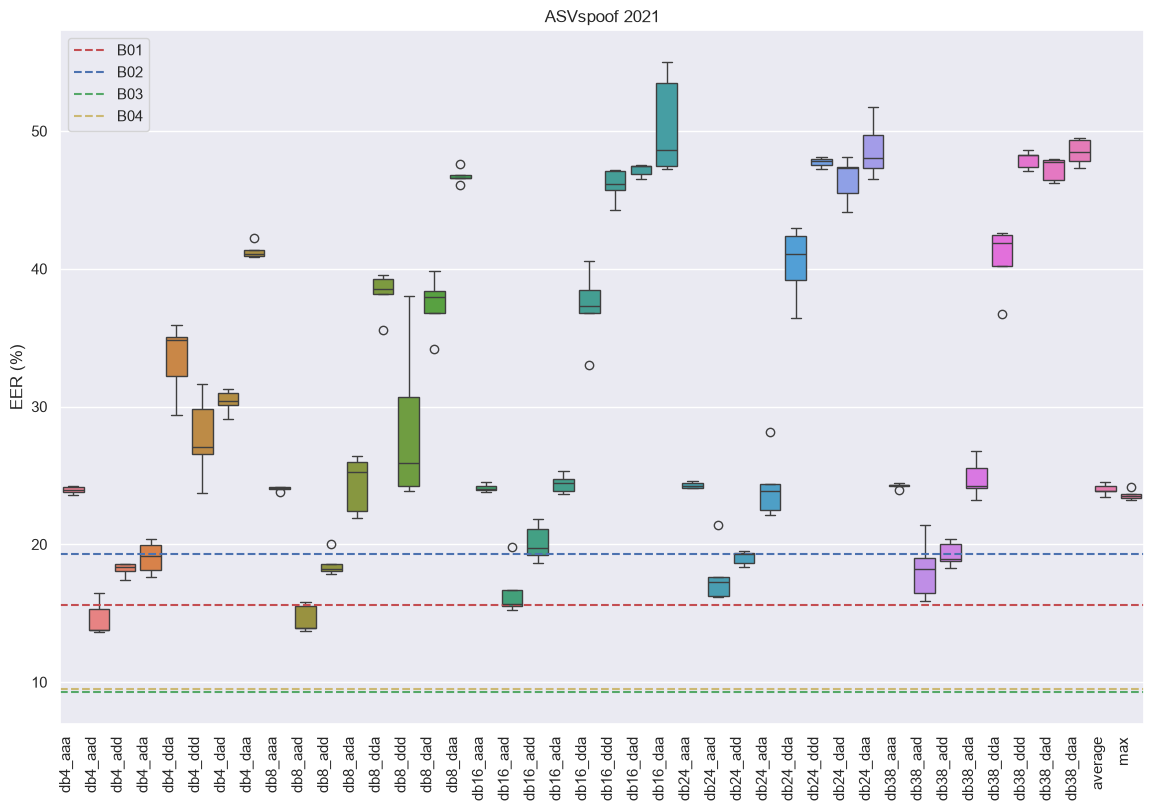

In [69]:
sns.set_theme(rc={'figure.figsize':(11.7,8.27)})
sns.boxplot(data=autorank_input_2021)
plt.title("ASVspoof 2021")

baseline_b03 = 9.26
baseline_b04 = 9.50
baseline_b01 = 15.62
baseline_b02 = 19.30

plt.axhline(baseline_b01, color='r', linestyle='--', label='B01')
plt.axhline(baseline_b02, color='b', linestyle='--', label='B02')
plt.axhline(baseline_b03, color='g', linestyle='--', label='B03')
plt.axhline(baseline_b04, color='y', linestyle='--', label='B04')

plt.xticks(rotation=90, ha='right')

plt.xlabel("")
plt.ylabel("EER (%)")
plt.tight_layout()
plt.legend(loc="upper left")
plt.show()

In [70]:
result_2021 = autorank(autorank_input_2021, alpha=0.05, verbose=False, order='ascending')
print(result_2021)

          meanrank       mean       std   ci_lower   ci_upper effect_size  \
db4_aad        1.6  14.585125  1.236685  10.035482  19.134769         0.0   
db8_aad        1.6  14.593569  0.994919  10.933358  18.253779   -0.007523   
db16_aad       4.4  16.576846  1.885976   9.638525  23.515168   -1.248943   
db38_aad       5.4  18.199720  2.212488  10.060193  26.339247   -2.016764   
db24_aad       5.4  17.744654  2.148316    9.84121  25.648098   -1.802556   
db4_add        6.0  18.185870  0.484747  16.402533  19.969206    -3.83365   
db8_add        6.8  18.547612  0.853810  15.406529  21.688696    -3.72893   
db4_ada        8.0  19.059183  1.168035  14.762096   23.35627   -3.719547   
db24_add       8.2  19.036338  0.499695   17.19801  20.874666   -4.719489   
db38_add       9.0  19.274021  0.888734  16.004454  22.543588   -4.354244   
db16_add       9.6  20.117804  1.339613    15.1895  25.046108   -4.291638   
max           13.6  23.568178  0.373097  22.195591  24.940765   -9.834765   

In [71]:
create_report(result_2021)

The statistical analysis was conducted for 42 populations with 5 paired samples.
The family-wise significance level of the tests is alpha=0.050.
We failed to reject the null hypothesis that the population is normal for all populations (minimal observed p-value=0.050). Therefore, we assume that all populations are normal.
We applied Bartlett's test for homogeneity and reject the null hypothesis (p=0.000) that thedata is homoscedastic. Thus, we assume that our data is heteroscedastic.
Because we have more than two populations and the populations are normal but heteroscedastic, we use the non-parametric Friedman test as omnibus test to determine if there are any significant differences between the mean values of the populations. We use the post-hoc Nemenyi test to infer which differences are significant. We report the mean value (M), the standard deviation (SD) and the mean rank (MR) among all populations over the samples. Differences between populations are significant, if the difference

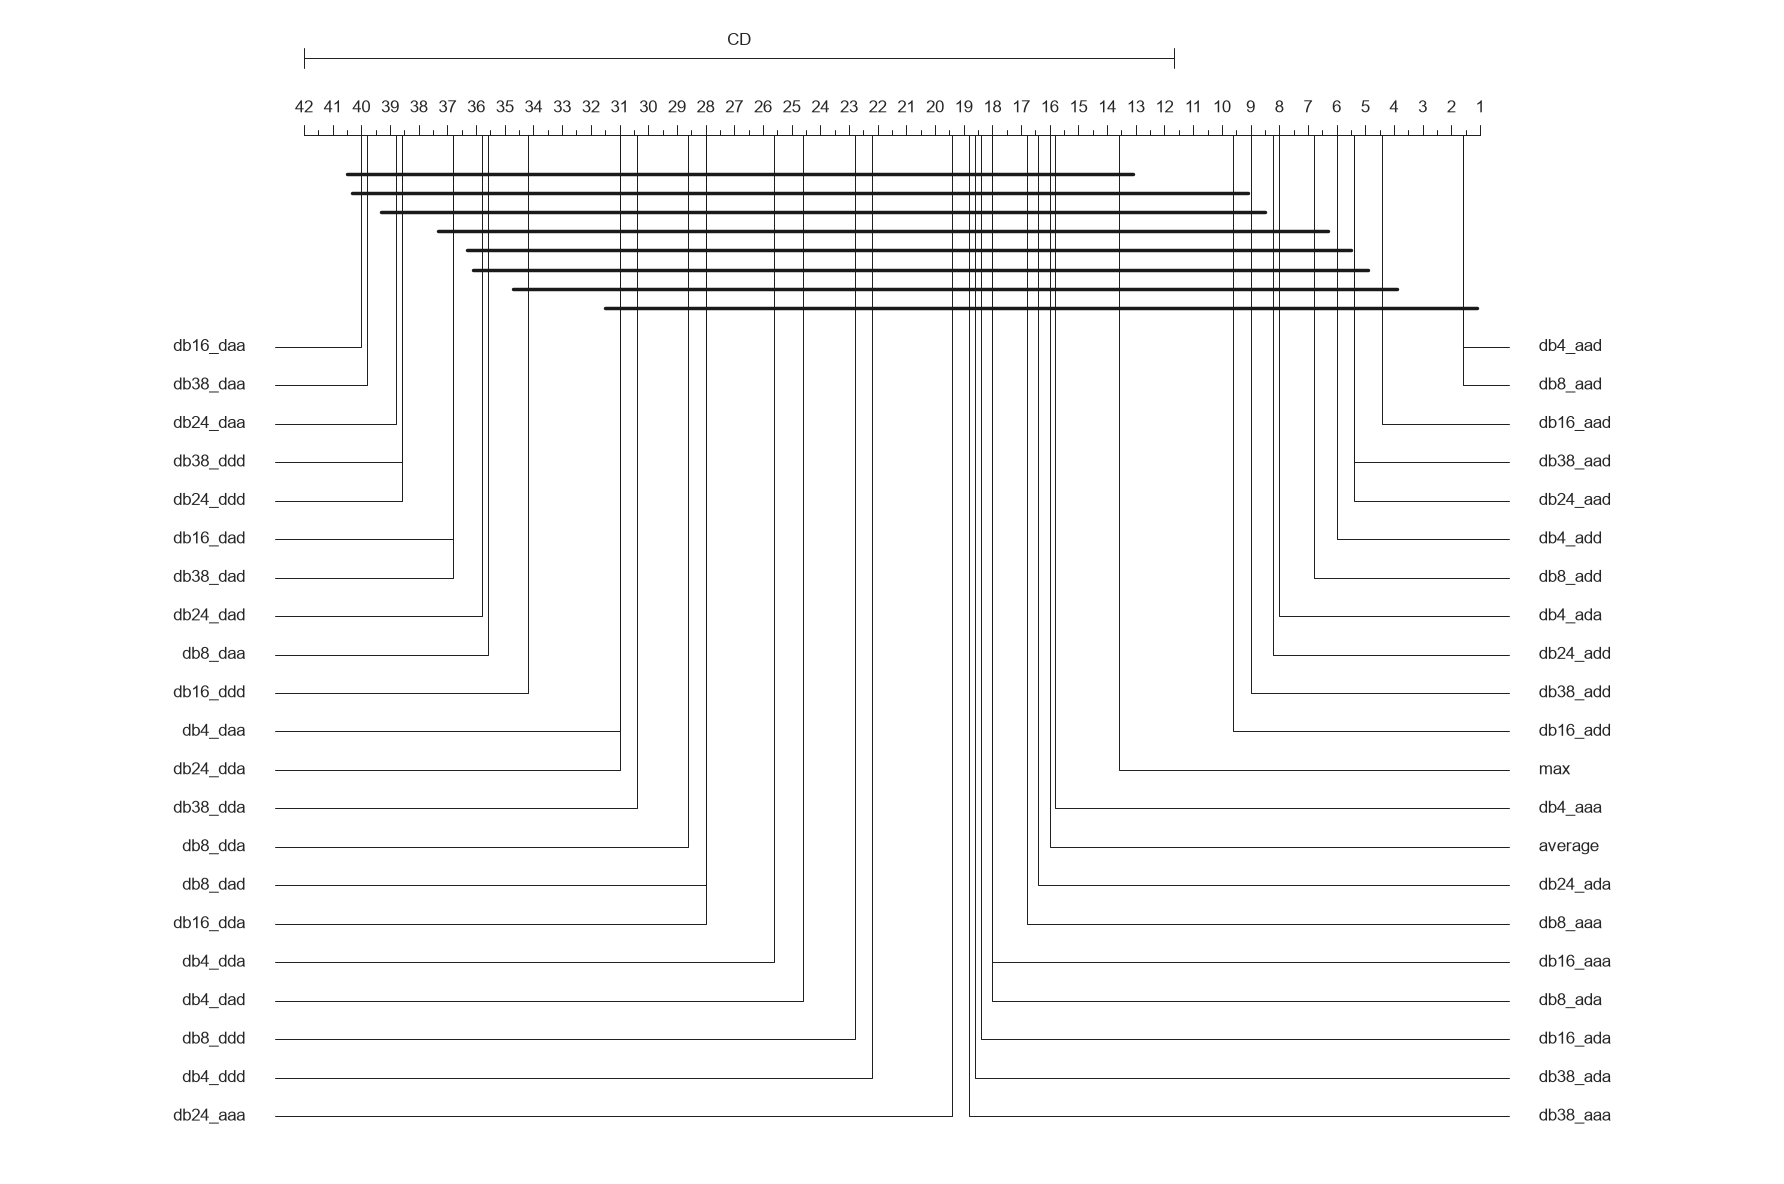

In [72]:
fig, ax = plt.subplots(figsize=(18, 12))

plot_stats(
    result_2021,
    allow_insignificant=True,
    ax=ax
)

plt.tight_layout()
plt.show()

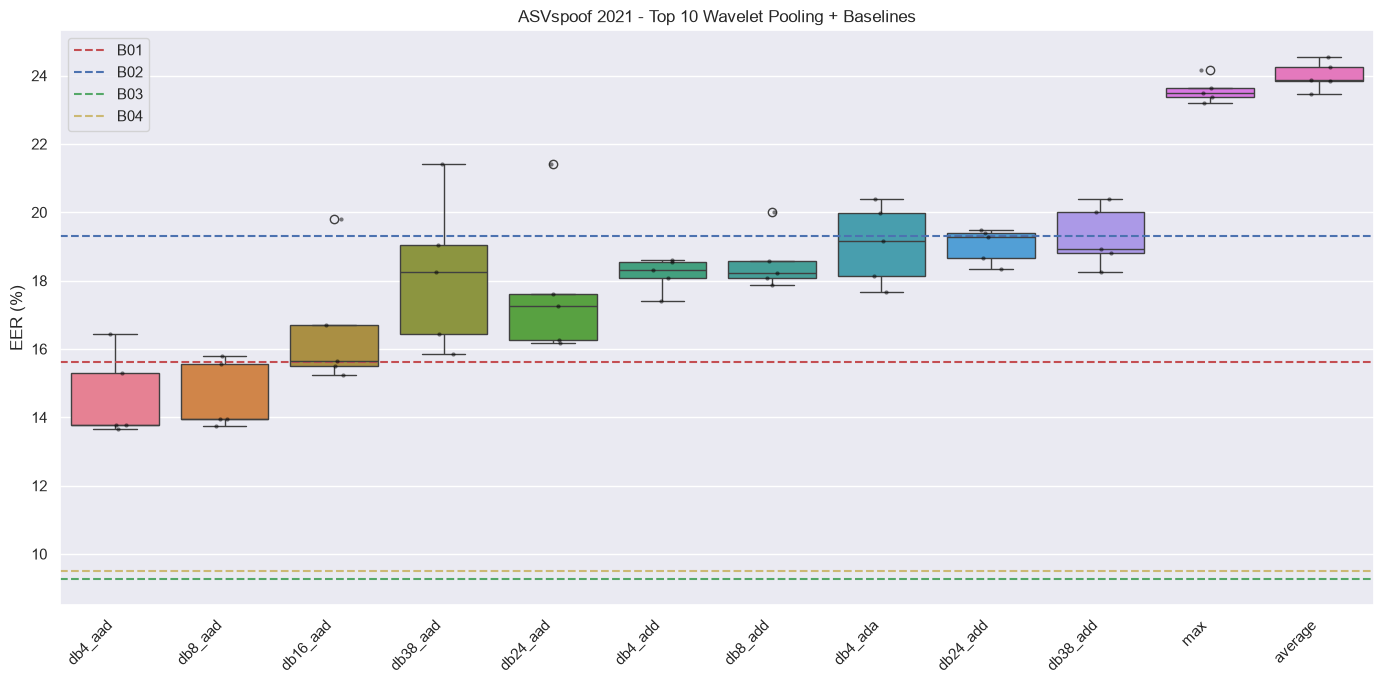

In [73]:
autorank_2021_ranking = result_2021[0]

top_10_results_ranking = autorank_2021_ranking[:10]

top_10_results = autorank_input_2021[
    top_10_results_ranking.index
].copy()

# Adicionar Max e Average Pooling
top_10_results["max"] = autorank_input_2021["max"]
top_10_results["average"] = autorank_input_2021["average"]

plt.figure(figsize=(14, 7))

sns.boxplot(data=top_10_results)
sns.stripplot(
    data=top_10_results,
    color="black",
    alpha=0.5,
    size=3
)

plt.title("ASVspoof 2021 - Top 10 Wavelet Pooling + Baselines")

baseline_b03 = 9.26
baseline_b04 = 9.50
baseline_b01 = 15.62
baseline_b02 = 19.30

plt.axhline(baseline_b01, color="r", linestyle="--", label="B01")
plt.axhline(baseline_b02, color="b", linestyle="--", label="B02")
plt.axhline(baseline_b03, color="g", linestyle="--", label="B03")
plt.axhline(baseline_b04, color="y", linestyle="--", label="B04")

plt.xticks(rotation=45, ha="right")

plt.xlabel("")
plt.ylabel("EER (%)")

plt.legend(loc="upper left")
plt.tight_layout()

plt.savefig("asv2021_top10_boxplot.pdf", bbox_inches="tight")
plt.show()

In [74]:
bayesian_result_2021 = autorank(
    autorank_input_2021, 
    alpha=0.05, 
    approach='bayesian', 
    rope=0.1,
    verbose=False, 
    order='ascending'
)

          meanrank       mean       std   ci_lower   ci_upper effect_size  \
db4_aad        1.6  14.585125  1.236685   2.765166  26.405084         0.0   
db8_aad        1.6  14.593569  0.994919   5.084353  24.102784   -0.007523   
db16_aad       4.4  16.576846  1.885976  -1.448892  34.602584   -1.248943   
db24_aad       5.4  17.744654  2.148316   -2.78847  38.277778   -1.802556   
db4_add        6.0  18.185870  0.484747  13.552766  22.818973    -3.83365   
db38_aad       5.4  18.199720  2.212488  -2.946746  39.346185   -2.016764   
db8_add        6.8  18.547612  0.853810  10.387087  26.708137    -3.72893   
db24_add       8.2  19.036338  0.499695  14.260367  23.812309   -4.719489   
db4_ada        8.0  19.059183  1.168035   7.895363  30.223003   -3.719547   
db38_add       9.0  19.274021  0.888734  10.779696  27.768346   -4.354244   
db16_add       9.6  20.117804  1.339613   7.314085  32.921523   -4.291638   
max           13.6  23.568178  0.373097  20.002202  27.134154   -9.834765   

In [75]:
create_report(bayesian_result_2021)

The statistical analysis was conducted for 42 populations with 5 paired samples.
The family-wise significance level of the tests is alpha=0.050.
We failed to reject the null hypothesis that the population is normal for all populations (minimal observed p-value=0.050). Therefore, we assume that all populations are normal.
We used a bayesian signed rank test to determine differences between the mean values of the populations and report the mean value (M) and the standard deviation (SD) for each population. We distinguish between populations being pair-wise smaller, equal, or larger and make a decision for one of these cases if we estimate that the posterior probability is at least alpha=0.050.
We used the effect size to define the region of practical equivalence (ROPE) around the mean value dynamically as 0.100*d.
We found significant and practically relevant differences between the populations db4_aad (M=14.585+-11.820, SD=1.237), db8_aad (M=14.594+-9.509, SD=0.995), db16_aad (M=16.577+

In [78]:
for coluna in autorank_input_2021.columns:
    dados_coluna = (autorank_input_2021[coluna].values,)
    
    res_boot = bootstrap(dados_coluna, np.mean, n_resamples=2000, confidence_level=0.95, method='BCa')
    
    ci_inferior, ci_superior = res_boot.confidence_interval.low, res_boot.confidence_interval.high
    print(f"{coluna}: Média = {np.mean(dados_coluna):.4f} | IC 95% = ({ci_inferior:.4f}, {ci_superior:.4f})")

db4_aaa: Média = 23.9455 | IC 95% = (23.6797, 24.1344)
db4_aad: Média = 14.5851 | IC 95% = (13.7248, 15.7085)
db4_add: Média = 18.1859 | IC 95% = (17.6685, 18.4745)
db4_ada: Média = 19.0592 | IC 95% = (18.2101, 19.9751)
db4_dda: Média = 33.4737 | IC 95% = (30.5224, 35.1783)
db4_ddd: Média = 27.7631 | IC 95% = (25.2929, 29.9995)
db4_dad: Média = 30.3778 | IC 95% = (29.6316, 30.9776)
db4_daa: Média = 41.2841 | IC 95% = (40.9809, 41.9500)
db8_aaa: Média = 24.0453 | IC 95% = (23.8890, 24.1243)
db8_aad: Média = 14.5936 | IC 95% = (13.8588, 15.3770)
db8_add: Média = 18.5476 | IC 95% = (18.0891, 19.5748)
db8_ada: Média = 24.3995 | IC 95% = (22.7733, 25.8793)
db8_dda: Média = 38.2336 | IC 95% = (36.3150, 39.0992)
db8_ddd: Média = 28.5613 | IC 95% = (25.1675, 35.1136)
db8_dad: Média = 37.4392 | IC 95% = (35.4844, 38.7933)
db8_daa: Média = 46.7469 | IC 95% = (46.3988, 47.2424)
db16_aaa: Média = 24.1252 | IC 95% = (23.9325, 24.3885)
db16_aad: Média = 16.5768 | IC 95% = (15.5659, 18.9454)
db16_add

## Plots

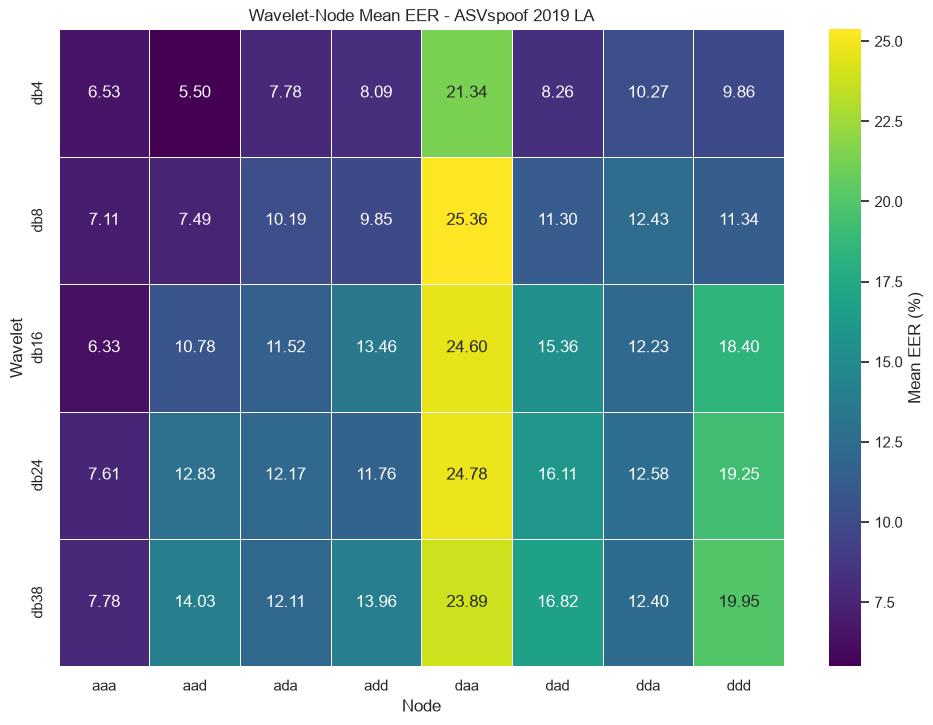

In [52]:
df = autorank_input_2019.copy()

df = df.loc[:, ~df.columns.isin(["max", "average"])]

df.columns = pd.MultiIndex.from_tuples(
    [col.split("_", 1) for col in df.columns],
    names=["Wavelet", "Node"]
)

mean_eer = df.mean(axis=0).unstack("Node")

mean_eer = mean_eer.sort_index(
    key=lambda idx: idx.map(lambda x: int(x.replace("db", "")))
)

sns.heatmap(
    mean_eer,
    annot=True,
    fmt=".2f",
    cmap="viridis",
    linewidths=.5,
    cbar_kws={"label": "Mean EER (%)"}
)

plt.title("Wavelet-Node Mean EER - ASVspoof 2019 LA")

plt.show()

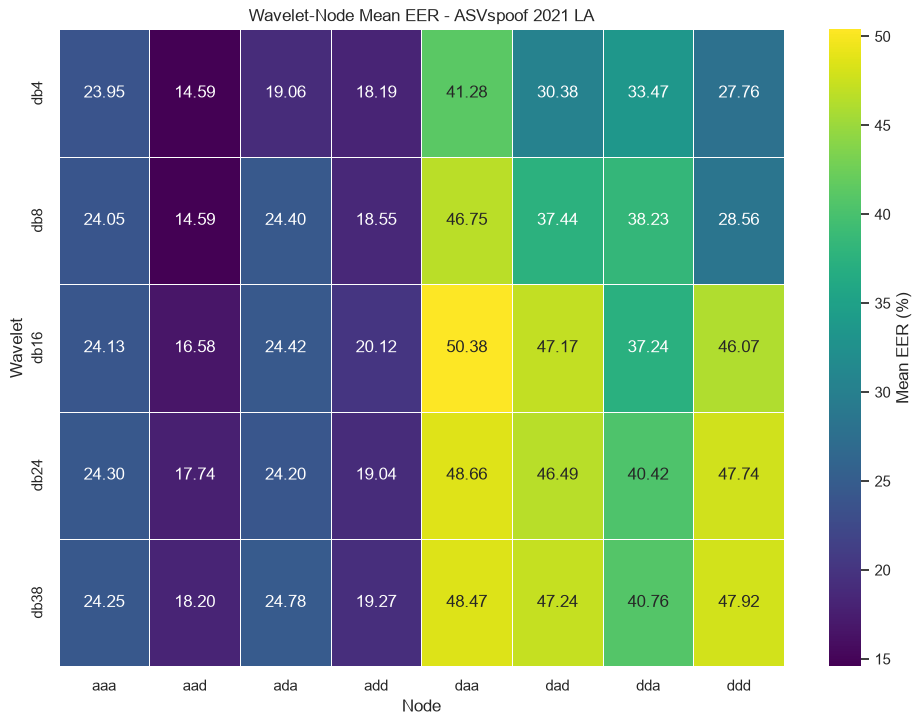

In [53]:
df_2021 = autorank_input_2021.copy()

df_2021 = df_2021.loc[:, ~df_2021.columns.isin(["max", "average"])]

df_2021.columns = pd.MultiIndex.from_tuples(
    [col.split("_", 1) for col in df_2021.columns],
    names=["Wavelet", "Node"]
)

mean_eer_2021 = df_2021.mean(axis=0).unstack("Node")

mean_eer_2021 = mean_eer_2021.sort_index(
    key=lambda idx: idx.map(lambda x: int(x.replace("db", "")))
)

sns.heatmap(
    mean_eer_2021,
    annot=True,
    fmt=".2f",
    cmap="viridis",
    linewidths=.5,
    cbar_kws={"label": "Mean EER (%)"}
)

plt.title("Wavelet-Node Mean EER - ASVspoof 2021 LA")

plt.show()

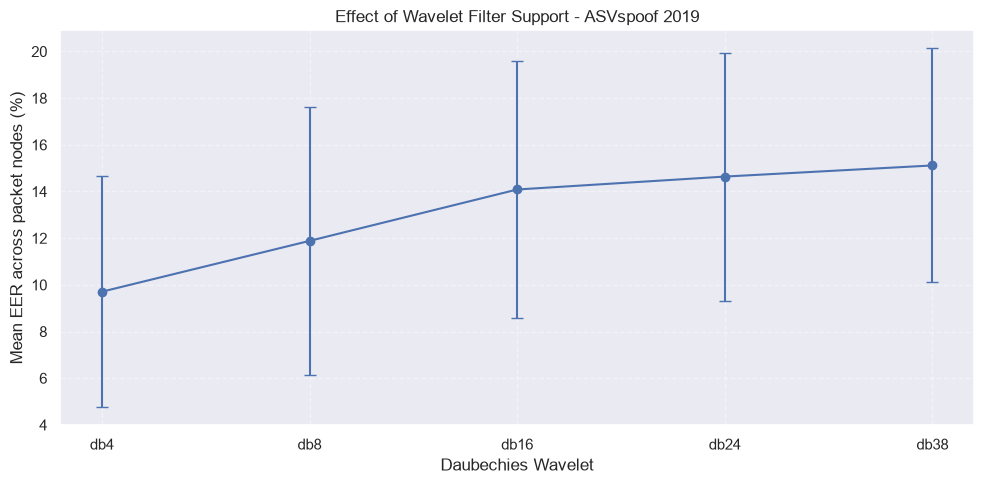

In [45]:
filter_mean = mean_eer.mean(axis=1)
filter_std = mean_eer.std(axis=1)

fig, ax = plt.subplots(figsize=(10, 5))

ax.errorbar(
    filter_mean.index,
    filter_mean.values,
    yerr=filter_std.values,
    marker="o",
    capsize=4,
    linewidth=1.5
)

ax.set_xlabel("Daubechies Wavelet")
ax.set_ylabel("Mean EER across packet nodes (%)")
ax.set_title("Effect of Wavelet Filter Support - ASVspoof 2019")
ax.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

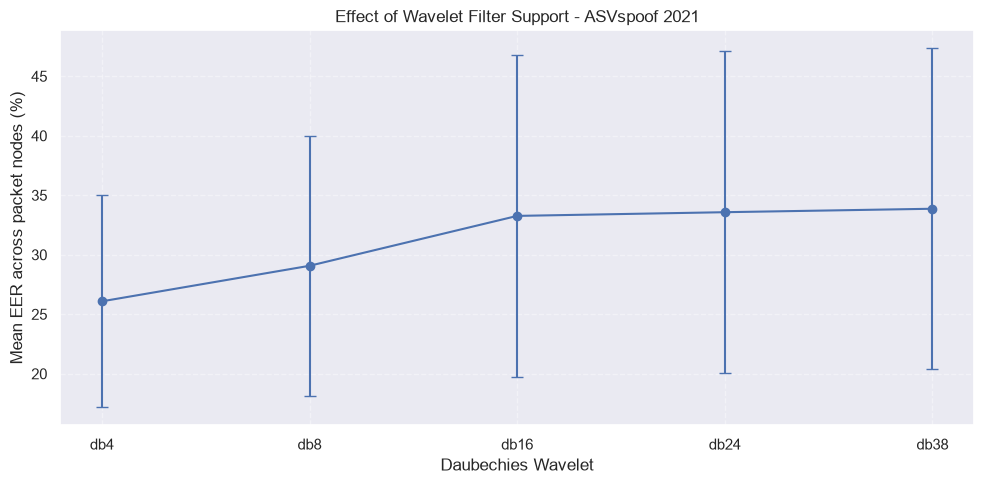

In [46]:
filter_mean_2021 = mean_eer_2021.mean(axis=1)
filter_std_2021 = mean_eer_2021.std(axis=1)

fig, ax = plt.subplots(figsize=(10, 5))

ax.errorbar(
    filter_mean_2021.index,
    filter_mean_2021.values,
    yerr=filter_std_2021.values,
    marker="o",
    capsize=4,
    linewidth=1.5
)

ax.set_xlabel("Daubechies Wavelet")
ax.set_ylabel("Mean EER across packet nodes (%)")
ax.set_title("Effect of Wavelet Filter Support - ASVspoof 2021")
ax.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

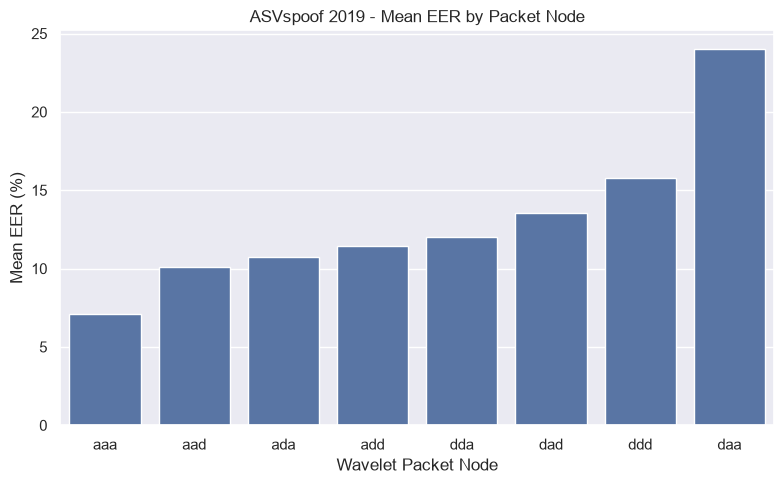

In [47]:
node_mean = mean_eer.mean(axis=0).sort_values()

plt.figure(figsize=(8, 5))

sns.barplot(
    x=node_mean.index,
    y=node_mean.values
)

plt.xlabel("Wavelet Packet Node")
plt.ylabel("Mean EER (%)")
plt.title("ASVspoof 2019 - Mean EER by Packet Node")

plt.tight_layout()
plt.show()

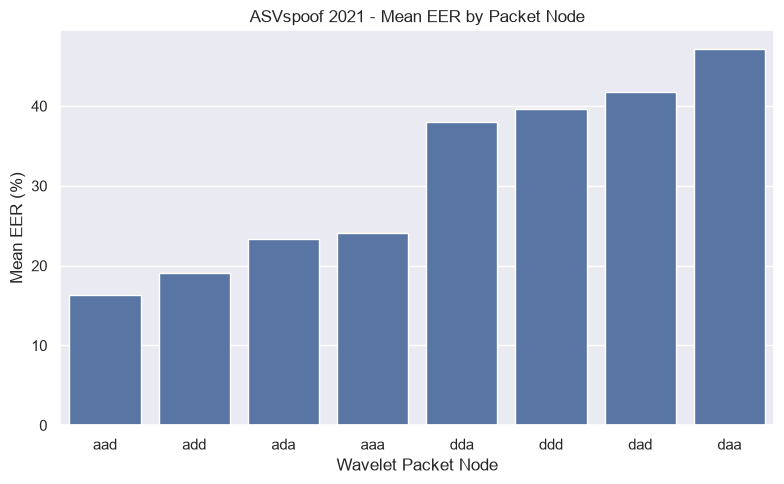

In [48]:
node_mean_2021 = mean_eer_2021.mean(axis=0).sort_values()

plt.figure(figsize=(8, 5))

sns.barplot(
    x=node_mean_2021.index,
    y=node_mean_2021.values
)

plt.xlabel("Wavelet Packet Node")
plt.ylabel("Mean EER (%)")
plt.title("ASVspoof 2021 - Mean EER by Packet Node")

plt.tight_layout()
plt.show()